# Flight Delay Prediction: American Airlines

In this notebook we build a model that predicts whether an **American Airlines (AA)** domestic flight will be delayed.

We use data from the **Bureau of Transportation Statistics (BTS)**, the *Reporting Carrier On-Time Performance* dataset. It has one row per US domestic flight, and we use all of 2025 (January–December).

## 1. Introduction

### Business question
> *"Can American Airlines' operations team use ML to predict flight delays (>15 min) before departure for proactive resource allocation?"*

Delays are expensive. A study funded by the FAA (Ball et al., 2010) estimated that flight delays cost the US economy **about $33 billion a year**. The costs land on airlines (crew, fuel, maintenance), on passengers (lost time) and on the wider economy.

If the operations team knows a flight is likely to be delayed, they can act before it happens. For example, they can have a spare aircraft or crew ready, move gate staff, or rebook passengers with tight connections.

### ML question
> *"Can we predict whether an American Airlines flight will arrive more than 15 minutes late, using only information available 2 hours before departure?"*

This is a **binary classification** problem:

- Each row is one scheduled AA flight.
- The target is `Delayed`. It is `1` if the flight arrives more than 15 minutes late (the official US Department of Transportation definition) and `0` otherwise.
- We make the prediction **2 hours before departure**. So we can only use what is known at that point: the schedule (date, time, route, distance), which aircraft is assigned (`Tail_Number`) and historical patterns. Anything we only learn at or after departure is off limits.

### Imports
All libraries are imported here in one place.

In [1]:
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from fairlearn.metrics import (
    MetricFrame,
    false_positive_rate,
    selection_rate,
    true_positive_rate,
)
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Consistent colour palette for all plots
COLOR_DELAYED = "#eb6834"  # orange: delayed
COLOR_ONTIME = "#2a78d6"   # blue: on time
COLOR_REF = "#8a8984"      # grey: reference line

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#ecebe7",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

RANDOM_STATE = 42

## 2. Data Loading & Cleaning

### 2.1 Download the raw data

BTS publishes one zip file per month. The cell below goes through all 12 months of 2025 and:

1. Downloads the zip file to `data/`, unless we already have it.
2. Reads the CSV file inside it with **all** of its columns (more than 100).
3. Keeps only the columns we need.

We do the column selection month by month. Loading all columns for 7 million flights at once would not fit in memory on a normal laptop.

These are the columns we keep:

| Column | Why we keep it |
|---|---|
| `FlightDate`, `Month`, `DayOfWeek`, `CRSDepTime` | When the flight is scheduled. Known in advance |
| `Origin`, `Dest`, `Distance` | The route. Known in advance |
| `Tail_Number` | Which aircraft flies it. Known 2 hours before departure |
| `Reporting_Airline` | So we can filter to AA |
| `Cancelled`, `Diverted` | So we can remove flights that never arrived |
| `ArrDelay` | To build the target |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Reasons for the delay. Used **only for exploration**, never as features |

In [2]:
YEAR = 2025
MONTHS = range(1, 13)
URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

DELAY_CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "LateAircraftDelay", "SecurityDelay"]
COLUMNS = [
    "FlightDate", "Month", "DayOfWeek", "Origin", "Dest", "CRSDepTime",
    "ArrDelay", "Cancelled", "Diverted", "Distance", "Tail_Number",
    *DELAY_CAUSES, "Reporting_Airline",
]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

monthly_frames = []

for month in MONTHS:
    url = URL_TEMPLATE.format(year=YEAR, month=month)
    zip_path = DATA_DIR / f"ontime_{YEAR}_{month:02d}.zip"

    # 1) Download (only if we don't already have the file)
    if not zip_path.exists():
        print(f"Downloading {url} ...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

    # 2) Read the CSV file directly from the zip, with all columns
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df_month = pd.read_csv(f, low_memory=False)

    print(f"{YEAR}-{month:02d}: {len(df_month):,} rows, {df_month.shape[1]} columns available")

    # 3) Keep only the columns we need
    monthly_frames.append(df_month[COLUMNS])

# 4) Combine all months into one DataFrame
raw = pd.concat(monthly_frames, ignore_index=True)
print(f"\nTotal: {len(raw):,} flights (all airlines), {raw.shape[1]} columns selected")

2025-01: 539,747 rows, 110 columns available


2025-02: 504,884 rows, 110 columns available


2025-03: 600,872 rows, 110 columns available


2025-04: 583,950 rows, 110 columns available


2025-05: 605,648 rows, 110 columns available


...

2025-09: 562,439 rows, 110 columns available


2025-10: 605,844 rows, 110 columns available


2025-11: 570,550 rows, 110 columns available


2025-12: 582,304 rows, 110 columns available



Total: 7,001,619 flights (all airlines), 17 columns selected


### 2.2 Keep only American Airlines

The dataset covers every US airline. We keep only AA's flights. After that, every row has the same airline, so we drop the `Reporting_Airline` column.

In [3]:
df = raw[raw["Reporting_Airline"] == "AA"].drop(columns=["Reporting_Airline"])

print(f"AA flights: {len(df):,} of {len(raw):,} ({len(df) / len(raw):.1%})")

AA flights: 973,653 of 7,001,619 (13.9%)


### 2.3 Remove cancelled and diverted flights

A cancelled flight never takes off, and a diverted flight lands somewhere else. Neither has a real arrival delay, so we can't say whether they were "late". We remove them.

After that, the `Cancelled` and `Diverted` columns only contain 0, so we drop them too.

In [4]:
n_before = len(df)

df = df[(df["Cancelled"] != 1) & (df["Diverted"] != 1)]
df = df.drop(columns=["Cancelled", "Diverted"])

print(f"Removed {n_before - len(df):,} cancelled/diverted flights")
print(f"Remaining: {len(df):,} rows")

Removed 20,812 cancelled/diverted flights
Remaining: 952,841 rows


### 2.4 Remove rows with no arrival delay

We build the target from `ArrDelay`. If it is missing, we can't tell whether the flight was late, so we drop the row.

In [5]:
n_before = len(df)

df = df.dropna(subset=["ArrDelay"]).reset_index(drop=True)

print(f"Removed {n_before - len(df):,} rows with missing ArrDelay")
print(f"Remaining: {len(df):,} rows")

Removed 0 rows with missing ArrDelay
Remaining: 952,841 rows


### 2.5 Create the target: `Delayed`

We use the official definition: a flight is delayed if it arrives **more than 15 minutes** after its scheduled time.

- `Delayed = 1`: delayed (`ArrDelay > 15`)
- `Delayed = 0`: on time

In [6]:
df["Delayed"] = (df["ArrDelay"] > 15).astype(int)

### 2.6 Avoid cheating: target leakage

Our model has to predict 2 hours before departure. So it may only use information we actually have at that point. If it uses information from the future, it will look great in testing and fail in practice. This is called **target leakage**. Kapoor & Narayanan (2023) show it is one of the most common mistakes in machine learning projects.

Two groups of columns would leak the answer:

- **`ArrDelay` is the answer itself.** If we know how late a flight arrived, we already know whether it was delayed.
- **The delay cause columns** (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay`) are only filled in after the flight lands, and only when it was delayed. Using them would be cheating.

The delay causes are still useful for *understanding* delays, for example how many are caused by a late incoming aircraft. So we move them, together with `ArrDelay`, into a separate DataFrame called `delay_causes` for the exploration later. Then we remove them from the main dataset, so they can't end up as features by accident.

In [7]:
# Separate DataFrame for EDA: same index as df, so they can be joined again
delay_causes = df[["ArrDelay", *DELAY_CAUSES]].copy()

# Remove the leakage columns from the main dataset
df = df.drop(columns=["ArrDelay", *DELAY_CAUSES])

print("delay_causes:", delay_causes.shape)
print("df:          ", df.shape)
print("Columns in df:", list(df.columns))

delay_causes: (952841, 6)
df:           (952841, 9)
Columns in df: ['FlightDate', 'Month', 'DayOfWeek', 'Origin', 'Dest', 'CRSDepTime', 'Distance', 'Tail_Number', 'Delayed']


### 2.7 Strengths and limitations of the data

What the data does well:
- It contains every AA domestic flight in 2025, not a sample.
- It is an official source with the same definitions everywhere.
- A full year covers all seasons: winter storms, summer peaks and holidays.
- About 950,000 flights is plenty for training and testing.
- `Tail_Number` lets us follow each aircraft through its day.

What it can't tell us:
- There is no weather data, even though weather causes many delays.
- It only covers one year, so we can't check whether patterns hold in 2026.
- Removing cancelled flights hides the worst days, because cancellations cluster on bad days.
- International flights are not included.
- There is no operational data, such as passenger numbers, staffing or maintenance.
- It is observational data. We can find patterns, but not prove what causes delays.

### 2.8 Class balance

How many flights are delayed compared with on time?

This matters because accuracy can be misleading when the classes are uneven. A model that always says "on time" would be right most of the time and still be useless. We will handle this later with class weights and metrics such as ROC-AUC and PR-AUC.

              Count  Share
On time (0)  714611  75.0%
Delayed (1)  238230  25.0%


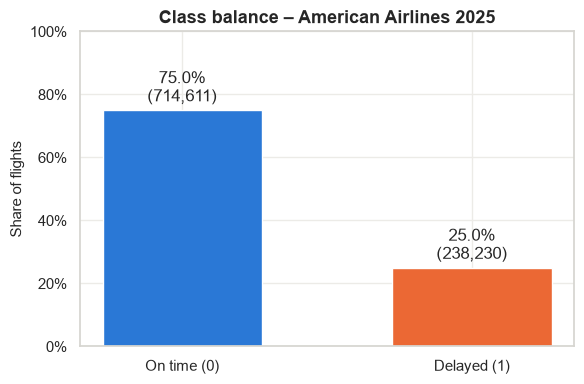

In [8]:
counts = df["Delayed"].value_counts().sort_index()
shares = counts / counts.sum()

balance = pd.DataFrame({"Count": counts, "Share": shares.map("{:.1%}".format)})
balance.index = ["On time (0)", "Delayed (1)"]
print(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, shares.values, color=[COLOR_ONTIME, COLOR_DELAYED], width=0.55)
ax.bar_label(bars, labels=[f"{s:.1%}\n({c:,})" for s, c in zip(shares, counts)], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_ylabel("Share of flights")
ax.set_title("Class balance – American Airlines 2025")
plt.tight_layout()
plt.show()

### 2.9 Save the cleaned datasets

We save two files, so the next sections can start from here without downloading and cleaning everything again:

- `cleaned_flights_aa.csv`: the main dataset we model on.
- `delay_causes_aa.csv`: `ArrDelay` and the delay causes, for exploration only. It has the same rows in the same order as the main dataset.

In [9]:
df.to_csv("cleaned_flights_aa.csv", index=False)
delay_causes.to_csv("delay_causes_aa.csv", index=False)

print(f"Saved cleaned_flights_aa.csv ({len(df):,} rows, {df.shape[1]} columns)")
print(f"Saved delay_causes_aa.csv ({len(delay_causes):,} rows, {delay_causes.shape[1]} columns)")
display(df.head())

Saved cleaned_flights_aa.csv (952,841 rows, 9 columns)
Saved delay_causes_aa.csv (952,841 rows, 6 columns)


,FlightDate,Month,DayOfWeek,Origin,Dest,CRSDepTime,Distance,Tail_Number,Delayed
0,2025-01-01,1,3,JFK,LAX,659,2475.0,N104NN,0
1,2025-01-02,1,4,JFK,LAX,659,2475.0,N110AN,0
2,2025-01-03,1,5,JFK,LAX,659,2475.0,N106NN,0
3,2025-01-04,1,6,JFK,LAX,700,2475.0,N117AN,0
4,2025-01-05,1,7,JFK,LAX,659,2475.0,N104NN,0


## 3. Exploratory Data Analysis

Before we build any models, we look at when and where AA's flights get delayed. This tells us which features are likely to be useful and what patterns the model should be able to pick up. Each plot below shows the **delay rate**: the share of flights that arrived more than 15 minutes late.

### 3.1 Load the data

We load the cleaned dataset and add one feature: `DepHour`, the scheduled departure hour.

`CRSDepTime` is stored as `hhmm` (e.g. `1435` = 14:35), so dividing by 100 and dropping the remainder gives the hour (14).

In [10]:
df = pd.read_csv("cleaned_flights_aa.csv")
df["DepHour"] = df["CRSDepTime"] // 100

OVERALL_RATE = df["Delayed"].mean()
print(f"Loaded {len(df):,} flights. Overall delay rate: {OVERALL_RATE:.1%}")


def add_reference(ax):
    """Draw the overall delay rate as a dashed reference line."""
    ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2,
               label=f"Overall average ({OVERALL_RATE:.1%})")
    ax.legend(frameon=False, loc="upper left")

Loaded 952,841 flights. Overall delay rate: 25.0%


### 3.2 Delay rate by departure hour

Does the time of day matter? If delays build up as aircraft fly several legs a day, later flights should be delayed more often.

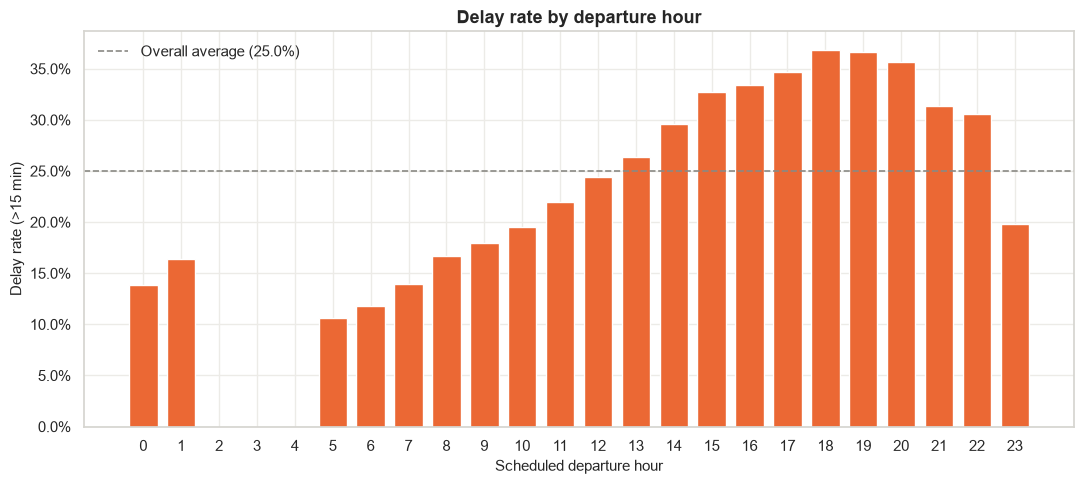

In [11]:
rate_hour = df.groupby("DepHour")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(rate_hour.index, rate_hour.values, color=COLOR_DELAYED, width=0.75)
add_reference(ax)

ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by departure hour")
plt.tight_layout()
plt.show()

**What we see:** The delay rate climbs steadily through the day. It goes from about 11% for 5 am departures to about 37% around 6–7 pm, before dropping late at night. There are almost no departures between 2 and 4 am, and very few around midnight.

**Why it matters:** This is the **cascade effect**. An aircraft flies several legs a day, and a delay on an early leg carries over to the next ones. `DepHour` will probably be one of the strongest features.

### 3.3 Delay rate by month

Are some times of year worse than others?

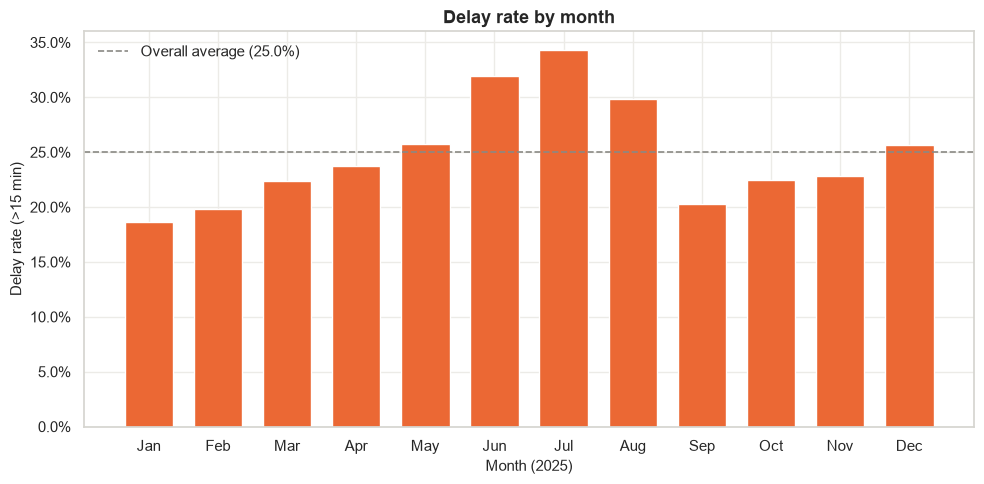

In [12]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

rate_month = df.groupby("Month")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(MONTH_NAMES, rate_month.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by month")
plt.tight_layout()
plt.show()

**What we see:** There is a clear **summer peak**. June and July are the worst months (32% and 34%), when traffic is high and thunderstorms are common. **December** is also above average (26%) because of holiday traffic and winter weather. January and February are the calmest months (19–20%).

**Why it matters:** `Month` captures seasonal patterns, so it should help the model. The effect is smaller than for departure hour, though.

### 3.4 Delay rate by day of week and distance

Two more features to check:

- **Day of week:** does traffic on certain days, such as busy weekend travel, lead to more delays?
- **Distance:** are long flights delayed more often than short ones? We group flights into 500-mile bins.

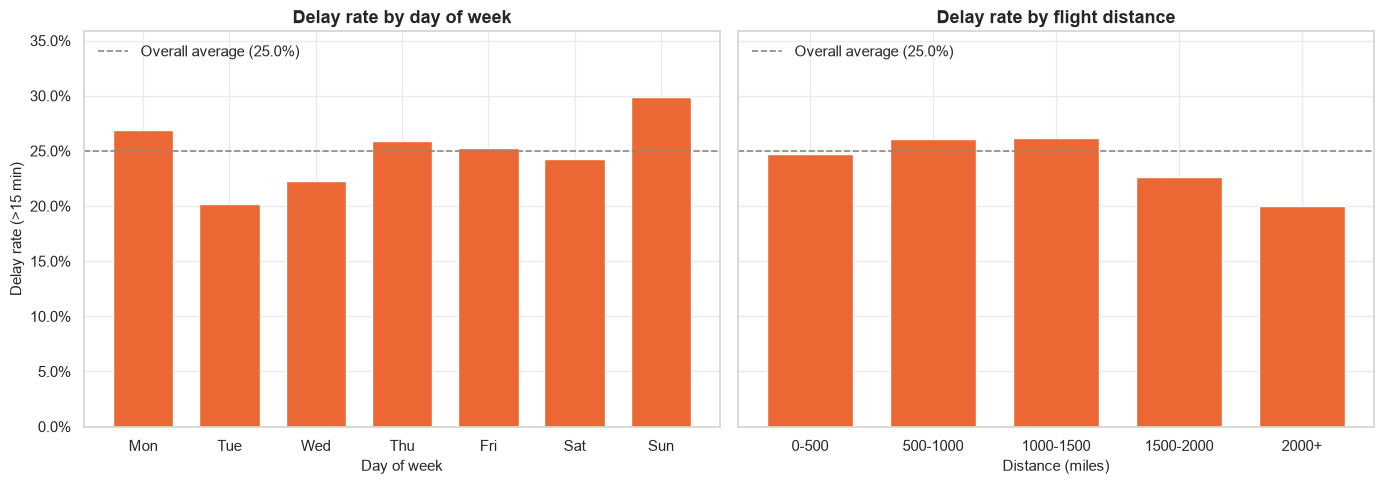

In [25]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
DISTANCE_BINS = [0, 500, 1000, 1500, 2000, np.inf]
DISTANCE_LABELS = ["0-500", "500-1000", "1000-1500", "1500-2000", "2000+"]

rate_weekday = df.groupby("DayOfWeek")["Delayed"].mean()
distance_bin = pd.cut(df["Distance"], bins=DISTANCE_BINS, labels=DISTANCE_LABELS, right=False)
rate_distance = df.groupby(distance_bin, observed=True)["Delayed"].mean()

fig, (ax_day, ax_dist) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax_day.bar(WEEKDAYS, rate_weekday.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_day)
ax_day.set_xlabel("Day of week")
ax_day.set_ylabel("Delay rate (>15 min)")
ax_day.set_title("Delay rate by day of week")

ax_dist.bar(DISTANCE_LABELS, rate_distance.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_dist)
ax_dist.set_xlabel("Distance (miles)")
ax_dist.set_title("Delay rate by flight distance")

ax_day.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_day.set_ylim(0, max(rate_weekday.max(), rate_distance.max()) * 1.2)
plt.tight_layout()
plt.show()

**What we see:** **Sunday** has the highest delay rate (30%), followed by Monday (27%). These are the busiest return-travel days after the weekend. Tuesday is the calmest day (20%). Saturday (24%) is actually slightly below average, so the effect is about Sunday and Monday rather than the weekend as a whole.

Distance makes little difference for most flights: everything up to 1,500 miles sits at 25–26%. Only the longest flights are delayed less often (23% for 1,500–2,000 miles and 20% for 2,000+). A likely reason is that long flights have more room in the schedule to make up lost time in the air.

**Why it matters:** `DayOfWeek` has a clear effect of about 10 percentage points between the best and worst day, so it is worth keeping. `Distance` is a weak feature on its own, but may still help in combination with route and airport.

### 3.5 Delay rate at AA's 10 busiest airports

AA runs a hub-and-spoke network: many flights go through a few large hubs. Are the hubs more delay-prone than other busy airports?

The five hubs (DFW, CLT, MIA, ORD, PHX) are shown in solid colour with bold labels. The other busy airports are shown in a lighter shade.

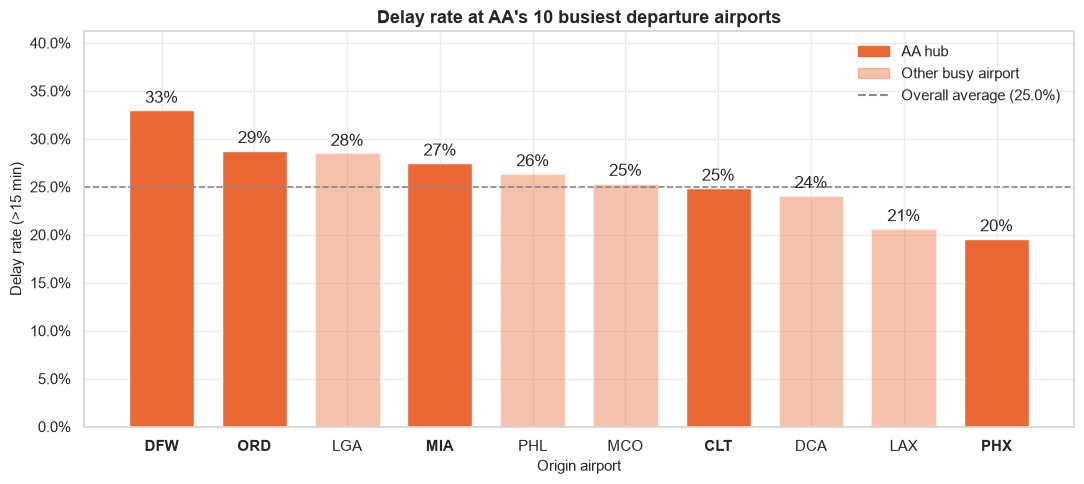

In [14]:
HUBS = ["DFW", "CLT", "MIA", "ORD", "PHX"]

top10 = df["Origin"].value_counts().head(10).index
rate_airport = (
    df[df["Origin"].isin(top10)]
    .groupby("Origin")["Delayed"].mean()
    .sort_values(ascending=False)
)
is_hub = rate_airport.index.isin(HUBS)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(rate_airport.index, rate_airport.values, color=COLOR_DELAYED, width=0.7)
for bar, hub in zip(bars, is_hub):
    bar.set_alpha(1.0 if hub else 0.4)
ax.bar_label(bars, labels=[f"{r:.0%}" for r in rate_airport.values], padding=3)

for label, hub in zip(ax.get_xticklabels(), is_hub):
    label.set_fontweight("bold" if hub else "normal")

ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=1.0, label="AA hub"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=0.4, label="Other busy airport"),
        plt.Line2D([], [], color=COLOR_REF, linestyle="--", label=f"Overall average ({OVERALL_RATE:.1%})"),
    ],
    frameon=False, loc="upper right",
)

ax.set_ylim(0, rate_airport.max() * 1.25)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Origin airport")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate at AA's 10 busiest departure airports")
plt.tight_layout()
plt.show()

**What we see:** Being a hub does not automatically mean more delays. **DFW**, AA's biggest hub, has the highest delay rate (33%), and ORD and MIA are also above average. But **CLT** (25%) is right at the average, and **PHX** (20%) has the lowest rate of the ten. Congested non-hub airports like LGA and PHL are also well above average.

**Why it matters:** Delay rates differ a lot between airports (20% to 33% among just these ten). So `Origin`, and probably `Dest`, carry useful information. A simple hub/non-hub flag would miss most of it, because the hubs themselves differ so much.

### 3.6 What causes the delays?

For every delayed flight, the airline reports how many minutes were caused by each of five reasons:

- **LateAircraftDelay:** the incoming aircraft arrived late (the cascade effect)
- **CarrierDelay:** the airline's own fault, e.g. crew, maintenance, baggage or fuelling
- **NASDelay:** the air traffic system, e.g. congestion or air traffic control
- **WeatherDelay:** extreme weather
- **SecurityDelay:** security problems, e.g. evacuations or long screening queues

For each delayed flight, we compute each cause's share of the total delay, then average those shares across all delayed flights.

**Note:** As explained in section 2.6, these columns are **not** used as features. They are only filled in after the flight lands, so using them would leak the answer. We use them here only to understand what drives delays.

Delayed flights: 238,230
Late aircraft (cascade)     41.2%
Carrier                     29.4%
Air traffic system (NAS)    25.2%
Weather                      4.0%
Security                     0.2%


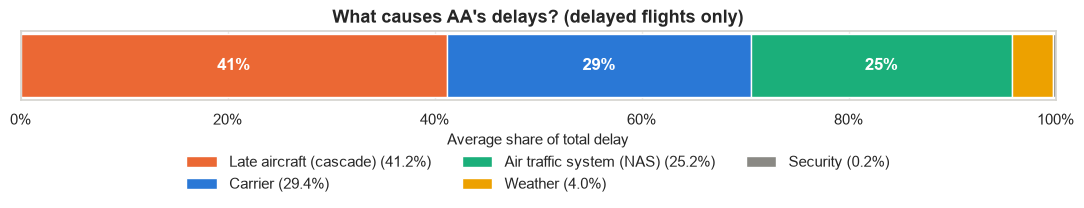

In [15]:
delay_causes = pd.read_csv("delay_causes_aa.csv")

CAUSE_LABELS = {
    "LateAircraftDelay": "Late aircraft (cascade)",
    "CarrierDelay": "Carrier",
    "NASDelay": "Air traffic system (NAS)",
    "WeatherDelay": "Weather",
    "SecurityDelay": "Security",
}
CAUSE_COLORS = [COLOR_DELAYED, COLOR_ONTIME, "#1baf7a", "#eda100", COLOR_REF]
causes = list(CAUSE_LABELS)

# Only delayed flights, where the causes are filled in
delayed = delay_causes[delay_causes["ArrDelay"] > 15]
total_minutes = delayed[causes].sum(axis=1)

# Each cause's share of the flight's total delay, averaged over all delayed flights
cause_share = (
    delayed[causes]
    .div(total_minutes, axis=0)[total_minutes > 0]
    .mean()
)
print(f"Delayed flights: {len(delayed):,}")
print(cause_share.rename(CAUSE_LABELS).map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
left = 0
for cause, color in zip(causes, CAUSE_COLORS):
    share = cause_share[cause]
    ax.barh(0, share, left=left, color=color, label=f"{CAUSE_LABELS[cause]} ({share:.1%})")
    if share > 0.05:
        ax.text(left + share / 2, 0, f"{share:.0%}", ha="center", va="center",
                color="white", fontweight="bold", fontsize=12)
    left += share

ax.set_xlim(0, 1)
ax.set_yticks([])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Average share of total delay")
ax.set_title("What causes AA's delays? (delayed flights only)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.6), ncol=3)
plt.tight_layout()
plt.show()

**What we see:** **Late aircraft** is the biggest cause, at about 41% of the average delay. The airline's own issues (carrier, about 29%) and the air traffic system (NAS, about 25%) come next. Extreme weather (about 4%) and security (under 1%) play a small part. Bad weather often shows up as NAS delays instead, because it slows down air traffic control.

**Why it matters:** The cascade effect is the single largest driver of delays. It also explains the departure-hour pattern in 3.2: the later in the day, the more earlier legs there are for a delay to build up on. Features that track an aircraft's previous legs (via `Tail_Number`) could therefore be valuable, as long as they only use information known 2 hours before departure.

### 3.7 Correlation matrix

Finally, we check the linear correlation between the numerical features and the target. A value near 0 means no linear relationship. Values near ±1 mean a strong one.

Two things to look for:
- **Feature vs. `Delayed`:** which features move together with delays?
- **Feature vs. feature:** are any features so strongly related that they carry the same information?

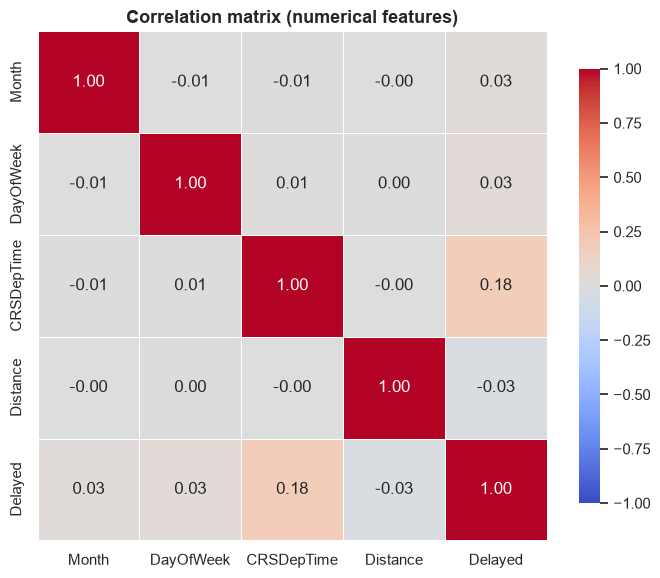

In [16]:
corr = df[["Month", "DayOfWeek", "CRSDepTime", "Distance", "Delayed"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
plt.tight_layout()
plt.show()

**What we see:** All correlations are weak. `CRSDepTime` has the strongest link to `Delayed` (0.18), which fits the departure-hour pattern. `Month`, `DayOfWeek` and `Distance` are close to 0. The features are also unrelated to each other, so there is no redundancy.

**Why it matters:** Correlation only measures *straight-line* relationships. The month effect goes up in summer and back down in autumn, so it has a near-zero correlation even though 3.3 showed a clear pattern. This is a reason to use models that can capture non-linear patterns, such as decision trees, random forests and XGBoost.

### 3.8 EDA summary

| Feature | Strength | Why |
|---|---|---|
| `DepHour` / `CRSDepTime` | Strong | Delay rate rises from 11% to 37% through the day (cascade effect) |
| `Origin` / `Dest` | Strong | Delay rates range from 20% to 33% among the 10 busiest airports alone |
| `Month` | Moderate | Clear summer peak (34% in July vs. 19% in January), but non-linear |
| `DayOfWeek` | Moderate | Ranges from 20% (Tuesday) to 30% (Sunday) |
| `Distance` | Weak | Flat at 25–26% up to 1,500 miles; only the longest flights are less delayed (20%) |
| Delay causes | Not a feature | Leakage, but show that late incoming aircraft are the biggest driver |